<h1 style="font-size:300%">👗 CLOTHING SORTER</h1>

This notebook is a demonstration of using [PyTorch Lightning](https://lightning.ai/pytorch-lightning) and transfer learning to fine tune a pretrained model for image classification to sort images of attire. We use a subset of the [Clothing Dataset](https://github.com/alexeygrigorev/clothing-dataset) by Alexey Grigorev. The data for this example is included in the git repo, so you can just clone this repo and run the notebook.

Bas S.H.T. Michielsen, 2025

Onderzoek vraag van Kamal: In hoeverre kan een vooraf getraind CNN schoenen en T-shirts herkennen wanneer alleen de nieuwe classificatielaag wordt getraind met een kleine dataset?

![banner](https://codeberg.org/Fontys/clothing_sorter/raw/branch/main/BANNER.jpg)

*Image by Stable Diffusion: a machine sorting clothing items and attire, colourful, funny*

### 1. Imports en instellingen

In [1]:
import collections, lightning, pandas, platform, os, torch, torchvision, warnings

from torch.utils.data import Dataset, DataLoader, random_split
from lightning import LightningDataModule, LightningModule, Trainer
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchmetrics import Precision, Recall
from torchmetrics.classification import MulticlassAccuracy
from lightning.pytorch.loggers import CSVLogger
from lightning.pytorch.callbacks import EarlyStopping
from PIL import Image

import matplotlib.pyplot as plt

lightning.seed_everything(42)

torch.set_float32_matmul_precision('high') # Increase precision for Nvidia Tensor Cores.

data_path = "data"

print("Versions: python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__, "| lightning", lightning.__version__)

Seed set to 42


Versions: python 3.14.7 | torch 2.14.0+cpu | torchvision 0.29.0+cpu | lightning 2.6.5


# ⛲ Data Source

Here we use a subset of the [Clothing Dataset](https://github.com/alexeygrigorev/clothing-dataset) by Alexey Grigorev. The original set contains 5000+ images of 20 different types of clothing. Because some types had just a few images, Alexey made a [top-10 smaller dataset](https://github.com/alexeygrigorev/clothing-dataset-small) that we use here. The dataset as provided had images already split into train/val/test, however we have combined them again so we can make our own splits (random if we want). The classes include Dress, Hat, Longsleeve, Outwear, Pants, Shirt, Shoes, Shorts, Skirt, T-Shirt, however the dataset is unbalanced, some classes have vastly more images than others.

# 🛠️ Data Preprocessing

The ResNet models are all pretrained on the ImageNet dataset, containing images of size 224 x 224 pixels. Consequently, in order to fine-tune this pretrained model we need to ensure that our input images are of the same size. To this purpose we prepare a transform here. The transform can accept loaded images, resize them and output a tensor for input to the model. After that we can create an Image Dataset for our images using the created transform.

### 2. Dataset laden

In [ ]:
# cel aangepast
image_size = (224, 224)

transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

#dataset = ImageFolder(data_path, transform=transform)
#classes = dataset.classes
#print("Created an image dataset for classes:\n", classes)

# Alle afbeeldingen en categorieën laden
volledige_dataset = ImageFolder(data_path, transform=transform)

# Alleen schoenen en T-shirts selecteren
print("Beschikbare categorieën:")
print(volledige_dataset.classes)

Beschikbare categorieën:
['dress', 'hat', 'longsleeve', 'outwear', 'pants', 'shirt', 'shoes', 'shorts', 'skirt', 't-shirt']


### 3. Dataset beperken tot schoenen en T-shirts

In [ ]:
# nieuw
import random
from torch.utils.data import Subset

# Twee categorieën selecteren
classes = ["shoes", "t-shirt"]

# Vaste selectie voor reproduceerbare resultaten
random.seed(42)

train_indices = []
validation_indices = []
test_indices = []

for categorie in classes:
    klasse_index = volledige_dataset.class_to_idx[categorie]

    # Alle afbeeldingen van deze categorie zoeken
    indices = [
        i for i, target in enumerate(volledige_dataset.targets)
        if target == klasse_index
    ]

    random.shuffle(indices)

    # Kleine dataset samenstellen
    train_indices.extend(indices[:10])
    validation_indices.extend(indices[10:14])
    test_indices.extend(indices[14:18])

train_dataset = Subset(volledige_dataset, train_indices)
validation_dataset = Subset(volledige_dataset, validation_indices)
test_dataset = Subset(volledige_dataset, test_indices)

print("Training:", len(train_dataset))
print("Validatie:", len(validation_dataset))
print("Test:", len(test_dataset))
print("Klassen:", classes)

Training: 20
Validatie: 8
Test: 8
Klassen: ['shoes', 't-shirt']


Here we print just a random sample of images and their labels, to get an idea about how the data looks.

### 4. Trainingsafbeeldingen visualiseren

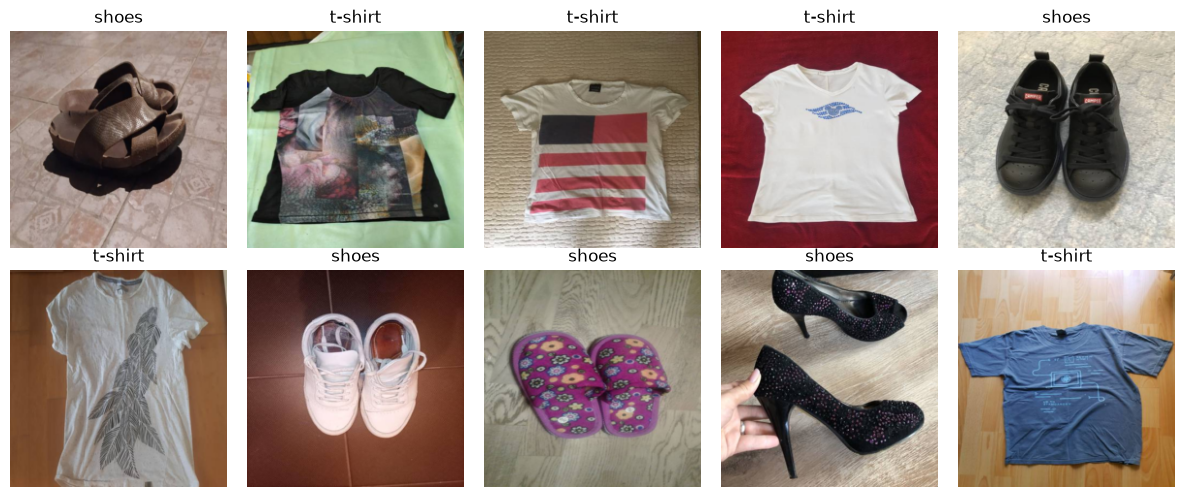

In [ ]:

# cel vervangen
sample_size = 10
indices = torch.randperm(len(train_dataset))[:sample_size]

sampled_images = [train_dataset[i][0] for i in indices]
sampled_targets = [train_dataset[i][1] for i in indices]

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(12, 5))

for i, (image, target) in enumerate(zip(sampled_images, sampled_targets)):
    ax = axes[i // 5, i % 5]
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(volledige_dataset.classes[target])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# nieuw

from torch.utils.data import DataLoader

batch_size = 4

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Eén batch controleren
afbeeldingen, targets = next(iter(train_loader))

print("Afbeeldingen:", afbeeldingen.shape)
print("Targets:", targets.tolist())


Afbeeldingen: torch.Size([4, 3, 224, 224])
Targets: [6, 9, 9, 9]



### 5. Transfer learning met ResNet18

ResNet18 is een CNN dat vooraf is getraind op ImageNet. De bestaande lagen worden bevroren, zodat hun gewichten tijdens de training niet veranderen.

De oorspronkelijke classificatielaag wordt vervangen door een nieuwe laag met twee uitvoerneuronen: schoenen en T-shirts. Alleen deze nieuwe laag wordt getraind.


In [ ]:
# nieuw

from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

# Voorgetraind model laden
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Bestaande lagen bevriezen
for parameter in model.parameters():
    parameter.requires_grad = False

# Nieuwe classificatielaag voor twee klassen
model.fc = nn.Linear(model.fc.in_features, 2)

# Aantal trainbare parameters controleren
aantal_trainbaar = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Trainbare parameters:", aantal_trainbaar)


Trainbare parameters: 1026



### 6. Training met PyTorch Lightning

PyTorch Lightning organiseert de training en validatie van het CNN. Alleen de nieuwe classificatielaag wordt bijgewerkt.

De oorspronkelijke targets 6 (schoenen) en 9 (T-shirts) worden tijdens de berekening omgezet naar 0 en 1.


In [ ]:
# nieuw

import lightning as L
import torch.nn.functional as F

class ClothingModel(L.LightningModule):
    def __init__(self, cnn):
        super().__init__()
        self.cnn = cnn

    def forward(self, afbeeldingen):
        return self.cnn(afbeeldingen)

    def training_step(self, batch, batch_idx):
        afbeeldingen, targets = batch

        # Oorspronkelijke targets omzetten: 6 -> 0, 9 -> 1
        targets = (targets == 9).long()

        scores = self(afbeeldingen)
        loss = F.cross_entropy(scores, targets)
        self.log("train_loss", loss, on_epoch=True, prog_bar=True)

        return loss

    def validation_step(self, batch, batch_idx):
        afbeeldingen, targets = batch
        targets = (targets == 9).long()

        scores = self(afbeeldingen)
        loss = F.cross_entropy(scores, targets)
        voorspellingen = scores.argmax(dim=1)
        accuracy = (voorspellingen == targets).float().mean()

        self.log("val_loss", loss, on_epoch=True)
        self.log("val_accuracy", accuracy, on_epoch=True, prog_bar=True)

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.cnn.fc.parameters(),
            lr=0.001
        )

lightning_model = ClothingModel(model)

print("Lightning-model aangemaakt.")


Lightning-model aangemaakt.



### 7. Training van de classificatielaag

Het voorgetrainde ResNet18-model wordt gedurende twee epochs getraind op 20 afbeeldingen. Alleen de nieuwe classificatielaag wordt aangepast.

Na iedere epoch wordt het model geëvalueerd op 8 validatieafbeeldingen. De trainingsloss en validatienauwkeurigheid worden bijgehouden.


In [ ]:

# nieuw
# Lightning Trainer instellen
trainer = L.Trainer(
    max_epochs=2,
    accelerator="cpu",
    devices=1,
    logger=False,
    enable_checkpointing=False,
    enable_model_summary=False,
    enable_progress_bar=True,
    num_sanity_val_steps=0
)

# Training en validatie uitvoeren
trainer.fit(
    lightning_model,
    train_dataloaders=train_loader,
    val_dataloaders=validation_loader
)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_c

Epoch 1: 100%|██████████| 5/5 [00:01<00:00,  2.56it/s, train_loss_step=0.802, val_accuracy=1.000, train_loss_epoch=0.658]

`Trainer.fit` stopped: `max_epochs=2` reached.


Epoch 1: 100%|██████████| 5/5 [00:01<00:00,  2.56it/s, train_loss_step=0.802, val_accuracy=1.000, train_loss_epoch=0.658]



### 8. Testen van het model

Het getrainde CNN wordt getest met 8 afbeeldingen die niet zijn gebruikt tijdens de training of validatie.

De testnauwkeurigheid geeft aan hoeveel afbeeldingen correct worden geclassificeerd.


In [ ]:
# nieuw

lightning_model.eval()

aantal_correct = 0
aantal_totaal = 0

with torch.no_grad():
    for afbeeldingen, targets in test_loader:
        # Targets omzetten: 6 -> 0, 9 -> 1
        targets = (targets == 9).long()

        scores = lightning_model(afbeeldingen)
        voorspellingen = scores.argmax(dim=1)

        aantal_correct += (voorspellingen == targets).sum().item()
        aantal_totaal += targets.size(0)

test_accuracy = 100 * aantal_correct / aantal_totaal

print(f"Correct: {aantal_correct} van {aantal_totaal}")
print(f"Testnauwkeurigheid: {test_accuracy:.1f}%")


Correct: 8 van 8
Testnauwkeurigheid: 100.0%



### 9. Model opslaan

De getrainde gewichten en biases van ResNet18 worden opgeslagen in een `.pth`-bestand.

De bestaande convolutionele lagen zijn afkomstig van het voorgetrainde model. Alleen de nieuwe classificatielaag is aangepast tijdens de training.

Het opgeslagen model kan later worden gebruikt om eigen foto's van schoenen en T-shirts te classificeren.


In [ ]:
# nieuw

from pathlib import Path

modelmap = Path("modellen")
modelmap.mkdir(exist_ok=True)

modelbestand = modelmap / "clothing_resnet18_transfer.pth"

torch.save(lightning_model.cnn.state_dict(), modelbestand)

print("Model opgeslagen:", modelbestand)


Model opgeslagen: modellen\clothing_resnet18_transfer.pth



### 10. Conclusie

In deze oefening is transfer learning toegepast met een vooraf getraind ResNet18-model om schoenen en T-shirts te classificeren.

De bestaande convolutionele lagen zijn bevroren. Alleen de nieuwe classificatielaag met 1026 trainbare parameters is gedurende twee epochs getraind op 20 afbeeldingen.

Het model behaalde een validatienauwkeurigheid van 100% (8/8) en een testnauwkeurigheid van 100% (8/8).

Deze resultaten laten zien dat de vooraf geleerde kenmerken bruikbaar zijn voor de nieuwe classificatietaak. Door de zeer kleine dataset kunnen echter geen betrouwbare conclusies worden getrokken over de prestaties op andere afbeeldingen.

Als vervolg wordt het opgeslagen model getest met twee eigen foto's: een schoen en een T-shirt.



### 11. Inference op eigen afbeeldingen

Het getrainde CNN wordt getest met zes eigen PNG-afbeeldingen, waaronder schoenen, slippers, een T-shirt, een hemd en een kledingstuk met lange mouwen.

De afbeeldingen zijn niet gebruikt tijdens de training of validatie. Het model voorspelt voor iedere afbeelding een van de twee aangeleerde klassen: `shoes` of `t-shirt`.

De voorspellingen en bijbehorende kansscores worden weergegeven om te onderzoeken hoe het model reageert op nieuwe en afwijkende afbeeldingen.


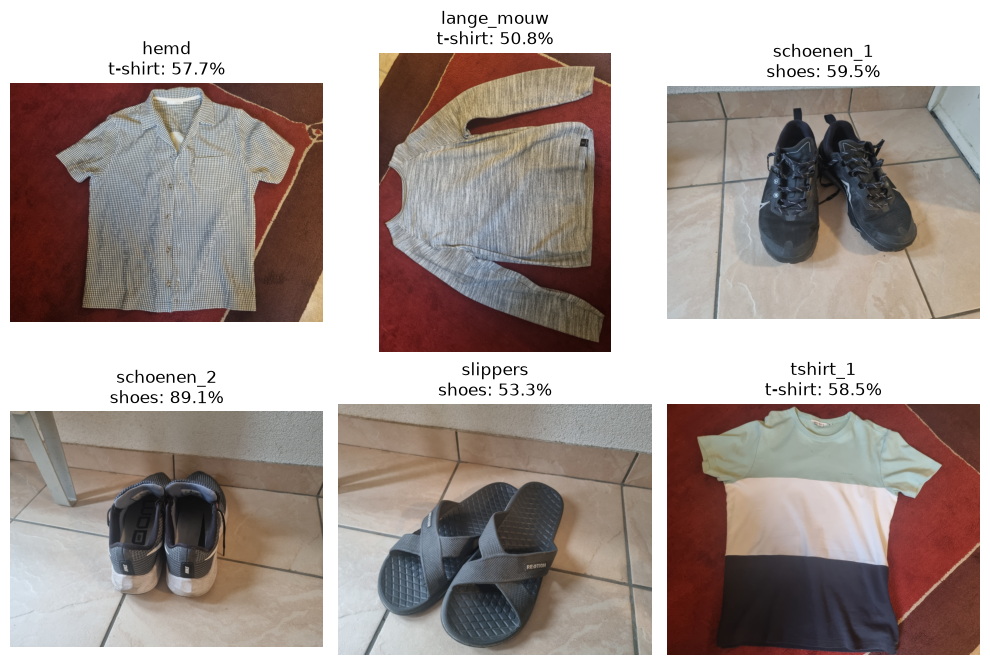

In [13]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Dezelfde afbeeldingsgrootte als tijdens de training
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Alle PNG-afbeeldingen verzamelen
fotobestanden = sorted(Path("inference").glob("*.png"))

lightning_model.eval()

fig, axes = plt.subplots(
    2, 3, figsize=(10, 7)
)

with torch.no_grad():
    for ax, bestand in zip(axes.flat, fotobestanden):
        afbeelding = Image.open(bestand).convert("RGB")
        invoer = inference_transform(afbeelding).unsqueeze(0)

        scores = lightning_model(invoer)
        kansen = torch.softmax(scores, dim=1)[0]

        voorspelling = kansen.argmax().item()
        klasse = classes[voorspelling]
        zekerheid = kansen[voorspelling].item() * 100

        ax.imshow(afbeelding)
        ax.set_title(f"{bestand.stem}\n{klasse}: {zekerheid:.1f}%")
        ax.axis("off")

plt.tight_layout()
plt.show()



### Resultatenanalyse op basis van eigen afbeeldingen

Het getrainde ResNet18-model is getest met zes eigen foto's: twee paar schoenen, slippers, een T-shirt, een hemd en een kledingstuk met lange mouwen.

Alle afbeeldingen zijn ingedeeld bij de verwachte brede categorie (`shoes` of `t-shirt`). De kansscores varieerden van 50,8% tot 89,1%.

Vooral bij de afwijkende afbeeldingen waren de scores laag. Het model kon deze afbeeldingen wel indelen maar maakte daarbij vaak nauwelijks onderscheid tussen de twee beschikbare klassen.

De resultaten laten zien dat transfer learning met een kleine dataset bruikbaar kan zijn. De hoge testnauwkeurigheid van 100% moet echter voorzichtig worden geïnterpreteerd vanwege de beperkte testset.

Het model kent bovendien uitsluitend twee klassen en kan daardoor geen afzonderlijke categorieën zoals slippers, hemd of lange mouwen voorspellen.


We extend the LightningDataModule create a DataModule that splits the dataset into Train, Validate and Test data, and provides specific loaders for them we need later. The reason that we split on 77.3% test data, 20% validation data, and 2.7% test data is that this produces exactly 100 test items.